# First Part

The first part focuses on exploring and preparing the air quality datasets for analysis. It covers the dataset structure, key variables, and data quality, providing the foundation for the following stages of the project.

# 1. Exploratory Data Analysis (EDA)

---

Student: Maria Jose Ospina

## Objective

This section aims to explore and understand the environmental datasets used in the project before applying more advanced analysis or Machine Learning techniques.

## 1.1 Dataset Loading

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [2]:
# Define the data directory
DATA_DIR = Path("datasets")

In [3]:
# List available files
files = list(DATA_DIR.glob("*"))

for file in files:
    print(file)

datasets/.DS_Store
datasets/RSQA - indice de la qualité de l'air (historique)
datasets/RSQA - Multi-Polluants (en continu)
datasets/liste-des-stations_do_rev_2026-05-22.csv
datasets/Projet - Station Nomade


In [4]:
# Define the dataset paths
AQI_PATH = DATA_DIR / "RSQA - indice de la qualité de l'air (historique)"
MULTI_POLLUTANTS_PATH = DATA_DIR / "RSQA - Multi-Polluants (en continu)"
STATION_REFERENCE_PATH = DATA_DIR / "liste-des-stations_do_rev_2026-05-22.csv"
STATION_NOMADE_PATH = DATA_DIR / "Projet - Station Nomade"

# Display the dataset paths
print("AQI:", AQI_PATH)
print("Multi-Pollutants:", MULTI_POLLUTANTS_PATH)
print("Station Reference:", STATION_REFERENCE_PATH)
print("Station Nomade:", STATION_NOMADE_PATH)

AQI: datasets/RSQA - indice de la qualité de l'air (historique)
Multi-Pollutants: datasets/RSQA - Multi-Polluants (en continu)
Station Reference: datasets/liste-des-stations_do_rev_2026-05-22.csv
Station Nomade: datasets/Projet - Station Nomade


In [5]:
# Inspect the contents of the dataset folders
print("AQI folder:")
for file in AQI_PATH.iterdir():
    print(" -", file.name)

print("\nMulti-Pollutants folder:")
for file in MULTI_POLLUTANTS_PATH.iterdir():
    print(" -", file.name)

AQI folder:
 - rsqa-indice-qualite-air-2019-2021.csv
 - rsqa-indice-qualite-air-2025-2027.csv
 - rsqa-indice-qualite-air-2013-2015.csv
 - rsqa-indice-qualite-air-2016-2018.csv
 - rsqa-indice-qualite-air-2022-2024.csv

Multi-Pollutants folder:
 - .DS_Store
 - rsqa-multi-polluants2018.csv
 - rsqa-multi-polluants2024.csv
 - rsqa-multi-polluants2025.csv
 - rsqa-multi-polluants2019.csv
 - rsqa-multi-polluants2021.csv
 - rsqa-multi-polluants2020.csv
 - rsqa-multi-polluants2022.csv
 - rsqa-multi-polluants2023.csv
 - rsqa-multi-polluants2013.csv
 - rsqa-multi-polluants2014.csv
 - rsqa-multi-polluants2015.csv
 - rsqa-multi-polluants2017.csv
 - rsqa-multi-polluants2016.csv


In [6]:
# Load all AQI files
aqi_files = sorted(AQI_PATH.glob("*.csv"))

aqi_data = {}

for file in aqi_files:
    df = pd.read_csv(file, low_memory=False)
    aqi_data[file.name] = df

# Load all Multi-Pollutants files
multi_files = sorted(MULTI_POLLUTANTS_PATH.glob("*.csv"))

multi_data = {}

for file in multi_files:
    df = pd.read_csv(file, low_memory=False)
    multi_data[file.name] = df


# Display a compact overview
print("AQI datasets")
print("-" * 60)

for name, df in aqi_data.items():
    print(f"{name}: {df.shape}")


print("\nMulti-Pollutants datasets")
print("-" * 60)

for name, df in multi_data.items():
    print(f"{name}: {df.shape}")

AQI datasets
------------------------------------------------------------
rsqa-indice-qualite-air-2013-2015.csv: (963639, 5)
rsqa-indice-qualite-air-2016-2018.csv: (1018011, 5)
rsqa-indice-qualite-air-2019-2021.csv: (1024982, 5)
rsqa-indice-qualite-air-2022-2024.csv: (1001708, 5)
rsqa-indice-qualite-air-2025-2027.csv: (334254, 5)

Multi-Pollutants datasets
------------------------------------------------------------
rsqa-multi-polluants2013.csv: (105408, 15)
rsqa-multi-polluants2014.csv: (96648, 16)
rsqa-multi-polluants2015.csv: (96360, 13)
rsqa-multi-polluants2016.csv: (96624, 13)
rsqa-multi-polluants2017.csv: (96360, 13)
rsqa-multi-polluants2018.csv: (96360, 17)
rsqa-multi-polluants2019.csv: (87600, 17)
rsqa-multi-polluants2020.csv: (96624, 17)
rsqa-multi-polluants2021.csv: (96360, 20)
rsqa-multi-polluants2022.csv: (96624, 17)
rsqa-multi-polluants2023.csv: (96624, 17)
rsqa-multi-polluants2024.csv: (96361, 19)
rsqa-multi-polluants2025.csv: (96360, 14)


In [7]:
# Inspect columns and sample rows for every dataset

print("=" * 80)
print("AQI DATASETS")
print("=" * 80)

for name, df in aqi_data.items():
    print(f"\n{name}")
    print("-" * 80)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))


print("\n" + "=" * 80)
print("MULTI-POLLUTANTS DATASETS")
print("=" * 80)

for name, df in multi_data.items():
    print(f"\n{name}")
    print("-" * 80)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))

AQI DATASETS

rsqa-indice-qualite-air-2013-2015.csv
--------------------------------------------------------------------------------
Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']

First 3 rows:


,stationId,polluant,valeur,date,heure
0,99,NO2,2,2013-08-05,3
1,99,PM,2,2013-08-05,3
2,3,SO2,4,2013-08-05,4



rsqa-indice-qualite-air-2016-2018.csv
--------------------------------------------------------------------------------
Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']

First 3 rows:


,stationId,polluant,valeur,date,heure
0,7,NO2,8,2016-01-28,21
1,80,SO2,1,2016-06-28,5
2,80,O3,15,2016-06-28,5



rsqa-indice-qualite-air-2019-2021.csv
--------------------------------------------------------------------------------
Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']

First 3 rows:


...

,NO_POSTE,DATE_HEURE,CO,H2S,NO,NO2,"PM2,5",O3,SO2,BC1_370nm,BC6_880nm,PUF,Benzene,Toluene,Ethylbenzene,MP-Xylene,O-Xylene
0,3,01-01-2023 01:00,N/M,1.167443,0.071864,6.083539,4.069281,11.76225,0,N/M,N/M,N/M,0.85209,1.47665,0.21103,0.698121,0.209529
1,3,01-01-2023 02:00,N/M,0.958055,0.321211,6.899487,4.207832,10.64294,0,N/M,N/M,N/M,0.957432,1.765699,0.258733,0.917765,0.289732
2,3,01-01-2023 03:00,N/M,0.939854,0.579838,7.988337,4.501887,9.440933,0,N/M,N/M,N/M,0.898514,1.552786,0.235969,0.778348,0.242409



rsqa-multi-polluants2024.csv
--------------------------------------------------------------------------------
Columns: ['NO_POSTE', 'DATE_HEURE', 'CO', 'H2S', 'NO', 'NO2', 'PM2.5', 'PST', 'PM10', 'O3', 'SO2', 'BC1_370nm', 'BC6_880nm', 'PUF', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']

First 3 rows:


,NO_POSTE,DATE_HEURE,CO,H2S,NO,NO2,PM2.5,PST,PM10,O3,SO2,BC1_370nm,BC6_880nm,PUF,Benzene,Toluene,Ethylbenzene,MP-Xylene,O-Xylene
0,3,01-01-2024 01:00,N/M,N/M,0.2,1.176645,2.782387,N/M,N/M,29.04014,0.029157,N/M,N/M,N/M,0.247791,0.19779,0,0.0425,0
1,3,01-01-2024 02:00,N/M,N/M,0.2,0.745464,2.12325,N/M,N/M,30.05707,0.023981,N/M,N/M,N/M,0.246915,0.213833,0,0.045,0
2,3,01-01-2024 03:00,N/M,N/M,0.2,0.248825,0.820056,N/M,N/M,31.46137,0.008134,N/M,N/M,N/M,0.217207,0.14,0,0,0.014999



rsqa-multi-polluants2025.csv
--------------------------------------------------------------------------------
Columns: ['NO_POSTE', 'DATE_HEURE', 'CO', 'H2S', 'NO', 'NO2', 'PM2.5', 'PST', 'PM10', 'O3', 'SO2', 'BC1_370nm', 'BC6_880nm', 'PUF']

First 3 rows:


,NO_POSTE,DATE_HEURE,CO,H2S,NO,NO2,PM2.5,PST,PM10,O3,SO2,BC1_370nm,BC6_880nm,PUF
0,3,01-01-2025 01:00,N/M,N/M,0,2.289455,4.264932,N/M,N/M,23.95098,0.310662,N/M,N/M,N/M
1,3,01-01-2025 02:00,N/M,N/M,0,1.64098,2.750272,N/M,N/M,23.78282,0.412423,N/M,N/M,N/M
2,3,01-01-2025 03:00,N/M,N/M,0,1.462702,2.767469,N/M,N/M,22.43873,0.153259,N/M,N/M,N/M


In [8]:
# Compare columns across all datasets

print("=" * 80)
print("AQI DATASETS")
print("=" * 80)

for name, df in aqi_data.items():
    print(f"{name}:")
    print(f"  Shape: {df.shape}")
    print(f"  Columns: {df.columns.tolist()}")


print("\n" + "=" * 80)
print("MULTI-POLLUTANTS DATASETS")
print("=" * 80)

for name, df in multi_data.items():
    print(f"{name}:")
    print(f"  Shape: {df.shape}")
    print(f"  Columns: {df.columns.tolist()}")

AQI DATASETS
rsqa-indice-qualite-air-2013-2015.csv:
  Shape: (963639, 5)
  Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']
rsqa-indice-qualite-air-2016-2018.csv:
  Shape: (1018011, 5)
  Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']
rsqa-indice-qualite-air-2019-2021.csv:
  Shape: (1024982, 5)
  Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']
rsqa-indice-qualite-air-2022-2024.csv:
  Shape: (1001708, 5)
  Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']
rsqa-indice-qualite-air-2025-2027.csv:
  Shape: (334254, 5)
  Columns: ['stationId', 'polluant', 'valeur', 'date', 'heure']

MULTI-POLLUTANTS DATASETS
rsqa-multi-polluants2013.csv:
  Shape: (105408, 15)
  Columns: ['NUMERO_STATION', 'DATE_HEURE', 'CO', 'NO', 'NO2', 'PM2.5', 'O3', 'SO2', 'PM10', 'PST', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
rsqa-multi-polluants2014.csv:
  Shape: (96648, 16)
  Columns: ['NUMERO_STATION', 'Date', 'heure', 'CO', 'NO', 'NO2', 'PM2.

In [9]:
# Identify common and year-specific columns in Multi-Pollutants

multi_columns = {
    name: set(df.columns)
    for name, df in multi_data.items()
}

all_multi_columns = set().union(*multi_columns.values())

print("ALL MULTI-POLLUTANTS COLUMNS")
print("-" * 60)

for column in sorted(all_multi_columns):
    years = [
        name.replace("rsqa-multi-polluants", "").replace(".csv", "")
        for name, columns in multi_columns.items()
        if column in columns
    ]
    
    print(f"{column:<20} -> {', '.join(years)}")


print("\n" + "=" * 60)
print("COLUMNS COMMON TO ALL YEARS")
print("=" * 60)

common_columns = set.intersection(*multi_columns.values())

for column in sorted(common_columns):
    print(column)


print("\n" + "=" * 60)
print("COLUMNS NOT PRESENT IN ALL YEARS")
print("=" * 60)

for column in sorted(all_multi_columns - common_columns):
    print(column)

ALL MULTI-POLLUTANTS COLUMNS
------------------------------------------------------------
BC1_370nm            -> 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
BC6_880nm            -> 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
Benzene              -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024
CO                   -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
DATE_ HEURE          -> 2015, 2016, 2017, 2018, 2019
DATE_HEURE           -> 2013, 2020, 2021, 2022, 2023, 2024, 2025
Date                 -> 2014
Ethylbenzene         -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024
H2S                  -> 2021, 2022, 2023, 2024, 2025
MP-Xylene            -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024
NO                   -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
NO2                  -> 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 202

In [10]:
# Display the exact column structure of each Multi-Pollutants file

for name, df in multi_data.items():
    year = name.replace("rsqa-multi-polluants", "").replace(".csv", "")
    print(f"{year}: {df.columns.tolist()}")

2013: ['NUMERO_STATION', 'DATE_HEURE', 'CO', 'NO', 'NO2', 'PM2.5', 'O3', 'SO2', 'PM10', 'PST', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
2014: ['NUMERO_STATION', 'Date', 'heure', 'CO', 'NO', 'NO2', 'PM2.5', 'O3', 'SO2', 'PM10', 'PST', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
2015: ['NO_POSTE', 'DATE_ HEURE', 'CO', 'NO', 'NO2', 'PM2,5', 'O3', 'SO2', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
2016: ['NO_POSTE', 'DATE_ HEURE', 'CO', 'NO', 'NO2', 'PM2,5', 'O3', 'SO2', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
2017: ['NO_POSTE', 'DATE_ HEURE', 'CO', 'NO', 'NO2', 'PM2,5', 'O3', 'SO2', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene']
2018: ['NO_POSTE', 'DATE_ HEURE', 'CO', 'NO', 'NO2', 'PM2,5', 'O3', 'SO2', 'BC1_370nm', 'BC6_880nm', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene', 'PST', 'PM10']
2019: ['NO_POSTE', 'DATE_ HEURE', 'CO', 'NO', 'NO2', 'PM2,5', 'O3', 'SO2', 'BC1_370nm', 

In [11]:
# Normalize and combine Multi-Pollutants data

multi_cleaned = []

for name, df in multi_data.items():
    temp = df.copy()
    
    year = int(name.replace("rsqa-multi-polluants", "").replace(".csv", ""))
    
    # Station
    if "NUMERO_STATION" in temp.columns:
        temp = temp.rename(columns={"NUMERO_STATION": "station_id"})
    
    if "NO_POSTE" in temp.columns:
        temp = temp.rename(columns={"NO_POSTE": "station_id"})
    
    # PM2.5
    if "PM2,5" in temp.columns:
        temp = temp.rename(columns={"PM2,5": "PM2.5"})
    
    # Date and time
    if "DATE_ HEURE" in temp.columns:
        temp = temp.rename(columns={"DATE_ HEURE": "date_heure"})
    
    elif "DATE_HEURE" in temp.columns:
        temp = temp.rename(columns={"DATE_HEURE": "date_heure"})
    
    elif "Date" in temp.columns and "heure" in temp.columns:
        temp["date_heure"] = (
            temp["Date"].astype(str).str.strip()
            + " "
            + temp["heure"].astype(str).str.strip()
        )
        temp = temp.drop(columns=["Date", "heure"])
    
    # Standardize names
    if "pst" in temp.columns:
        temp = temp.rename(columns={"pst": "PST"})
    
    if "pm10" in temp.columns:
        temp = temp.rename(columns={"pm10": "PM10"})
    
    temp["year"] = year
    temp["source_file"] = name
    
    multi_cleaned.append(temp)


# Combine all years

multi_combined = pd.concat(
    multi_cleaned,
    ignore_index=True,
    sort=False
)

multi_combined["date_heure"] = pd.to_datetime(
    multi_combined["date_heure"],
    errors="coerce"
)

multi_combined = multi_combined.sort_values(
    ["date_heure", "station_id"]
).reset_index(drop=True)


# Summary

print("Combined Multi-Pollutants dataset")
print("-" * 50)
print("Rows:", f"{len(multi_combined):,}")
print("Columns:", len(multi_combined.columns))

print("\nColumns:")
print(multi_combined.columns.tolist())

print("\nYears:")
print(sorted(multi_combined["year"].dropna().unique()))

print("\nRows by year:")
print(multi_combined["year"].value_counts().sort_index())

Combined Multi-Pollutants dataset
--------------------------------------------------
Rows: 1,254,313
Columns: 22

Columns:
['station_id', 'date_heure', 'CO', 'NO', 'NO2', 'PM2.5', 'O3', 'SO2', 'PM10', 'PST', 'Benzene', 'Toluene', 'Ethylbenzene', 'MP-Xylene', 'O-Xylene', 'year', 'source_file', 'BC1_370nm', 'BC6_880nm', 'site', 'H2S', 'PUF']

Years:
[np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Rows by year:
year
2013    105408
2014     96648
2015     96360
2016     96624
2017     96360
2018     96360
2019     87600
2020     96624
2021     96360
2022     96624
2023     96624
2024     96361
2025     96360
Name: count, dtype: int64


In [12]:
# Combine AQI data

aqi_cleaned = []

for name, df in aqi_data.items():
    temp = df.copy()
    
    # Extract years from filename
    period = name.replace("rsqa-indice-qualite-air-", "").replace(".csv", "")
    
    temp["source_file"] = name
    temp["period"] = period
    
    aqi_cleaned.append(temp)


aqi_combined = pd.concat(
    aqi_cleaned,
    ignore_index=True
)

# Convert date and time
aqi_combined["date"] = pd.to_datetime(
    aqi_combined["date"],
    errors="coerce"
)

# Summary
print("Combined AQI dataset")
print("-" * 50)
print("Rows:", f"{len(aqi_combined):,}")
print("Columns:", len(aqi_combined.columns))

print("\nColumns:")
print(aqi_combined.columns.tolist())

print("\nPeriods:")
print(aqi_combined["period"].value_counts().sort_index())

Combined AQI dataset
--------------------------------------------------
Rows: 4,342,594
Columns: 7

Columns:
['stationId', 'polluant', 'valeur', 'date', 'heure', 'source_file', 'period']

Periods:
period
2013-2015     963639
2016-2018    1018011
2019-2021    1024982
2022-2024    1001708
2025-2027     334254
Name: count, dtype: int64


In [13]:
# Check date ranges

print("AQI date ranges")
print("-" * 60)

for period, df in aqi_combined.groupby("period"):
    print(
        f"{period}: "
        f"{df['date'].min()} → {df['date'].max()}"
    )


print("\nMulti-Pollutants date range")
print("-" * 60)

print(
    f"{multi_combined['date_heure'].min()} → "
    f"{multi_combined['date_heure'].max()}"
)

AQI date ranges
------------------------------------------------------------
2013-2015: 2013-01-01 00:00:00 → 2015-12-31 00:00:00
2016-2018: 2016-01-01 00:00:00 → 2018-12-31 00:00:00
2019-2021: 2019-01-01 00:00:00 → 2021-12-31 00:00:00
2022-2024: 2022-01-01 00:00:00 → 2024-12-30 00:00:00
2025-2027: 2025-01-01 00:00:00 → 2026-01-18 00:00:00

Multi-Pollutants date range
------------------------------------------------------------
2013-01-01 01:00:00 → 2025-12-12 23:00:00


The available air-quality datasets were inspected and loaded while preserving all original records.

Two main datasets were consolidated:

* **Historical Air Quality Index (AQI):** five files covering 2013–2026.
* **Continuous Multi-Pollutants:** thirteen yearly files covering 2013–2025.

During the consolidation of the Multi-Pollutants data, differences in column names and formats between years were standardized without removing year-specific variables. All available pollutant measurements were retained, including variables that only appear during certain periods.

The resulting datasets contain:

* **AQI:** 4,342,594 records and 7 columns.
* **Multi-Pollutants:** 1,254,313 records and 22 columns.

The date ranges were also verified. The AQI data covers:

* 2013–2015
* 2016–2018
* 2019–2021
* 2022–2024
* 2025–2026

The Multi-Pollutants dataset covers **2013–2025**.

For the main analysis, the study period will be **2013–2025**. The AQI file labeled `2025-2027` will not be discarded because it contains valid observations from 2025 and part of 2026. The final analysis period will instead be defined through date filtering when required.

No records have been removed at this stage. Data-quality checks will be performed before applying any cleaning or filtering decisions.

## 1.2 Dataset Structure and Quality

In [23]:
# Missing values

print("AQI missing values")
print("-" * 60)

aqi_missing = aqi_combined.isna().sum()
aqi_missing_pct = (aqi_combined.isna().mean() * 100).round(2)

print(pd.DataFrame({
    "missing": aqi_missing,
    "missing_%": aqi_missing_pct
}))


print("\nMulti-Pollutants missing values")
print("-" * 60)

multi_missing = multi_combined.isna().sum()
multi_missing_pct = (multi_combined.isna().mean() * 100).round(2)

print(pd.DataFrame({
    "missing": multi_missing,
    "missing_%": multi_missing_pct
}))

AQI missing values
------------------------------------------------------------
             missing  missing_%
stationId          0        0.0
polluant           0        0.0
valeur             0        0.0
date               0        0.0
heure              0        0.0
source_file        0        0.0
period             0        0.0

Multi-Pollutants missing values
------------------------------------------------------------
              missing  missing_%
station_id         24       0.00
date_heure    1068841      85.21
CO                510       0.04
NO              22181       1.77
NO2             22182       1.77
PM2.5            2300       0.18
O3              29537       2.35
SO2             54890       4.38
PM10           483174      38.52
PST            483174      38.52
Benzene        184725      14.73
Toluene        184725      14.73
Ethylbenzene   184725      14.73
MP-Xylene      184725      14.73
O-Xylene       184725      14.73
year                0       0.00
source_fi

In [24]:
# Duplicate records

print("AQI duplicates")
print("-" * 60)

aqi_duplicate_count = aqi_combined.duplicated().sum()

print("Duplicated rows:", aqi_duplicate_count)


print("\nMulti-Pollutants duplicates")
print("-" * 60)

multi_duplicate_count = multi_combined.duplicated().sum()

print("Duplicated rows:", multi_duplicate_count)

AQI duplicates
------------------------------------------------------------
Duplicated rows: 0

Multi-Pollutants duplicates
------------------------------------------------------------
Duplicated rows: 55320


In [25]:
# Special and invalid values

print("AQI")
print("-" * 60)

print("AQI value statistics:")
print(aqi_combined["valeur"].describe())

print("\nNegative values:")
print((aqi_combined["valeur"] < 0).sum())

print("\nUnique pollutants:")
print(aqi_combined["polluant"].unique())


print("\nMulti-Pollutants")
print("-" * 60)

pollutant_columns = [
    "CO", "NO", "NO2", "PM2.5", "O3", "SO2",
    "PM10", "PST", "Benzene", "Toluene",
    "Ethylbenzene", "MP-Xylene", "O-Xylene",
    "BC1_370nm", "BC6_880nm", "H2S", "PUF"
]

available_pollutants = [
    col for col in pollutant_columns
    if col in multi_combined.columns
]

nm_counts = (
    multi_combined[available_pollutants]
    .eq("N/M")
    .sum()
    .sort_values(ascending=False)
)

print("N/M values by pollutant:")
print(nm_counts)

AQI
------------------------------------------------------------
AQI value statistics:
count    4.342594e+06
mean     7.734277e+00
std      8.650447e+00
min      0.000000e+00
25%      1.000000e+00
50%      4.000000e+00
75%      1.200000e+01
max      4.840000e+02
Name: valeur, dtype: float64

Negative values:
0

Unique pollutants:
<StringArray>
['NO2', 'PM', 'SO2', 'O3', 'CO']
Length: 5, dtype: str

Multi-Pollutants
------------------------------------------------------------
N/M values by pollutant:
Benzene         973392
Toluene         973392
O-Xylene        973392
MP-Xylene       973392
Ethylbenzene    973392
CO              736946
BC1_370nm       692546
BC6_880nm       692546
SO2             649080
PM10            631465
PST             631465
H2S             420745
PUF             411986
O3              175824
NO              132000
NO2             132000
PM2.5            44616
dtype: int64


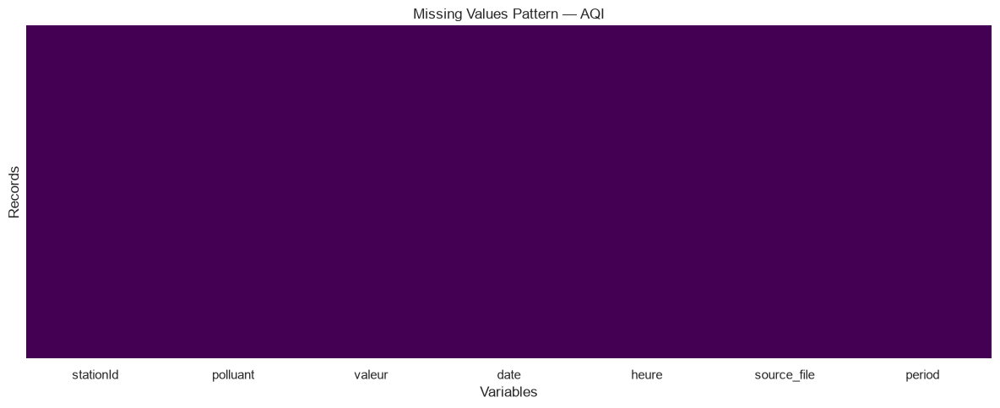

In [26]:
# Missing values heatmap — AQI

plt.figure(figsize=(12, 5))

sns.heatmap(
    aqi_combined.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Pattern — AQI")
plt.xlabel("Variables")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

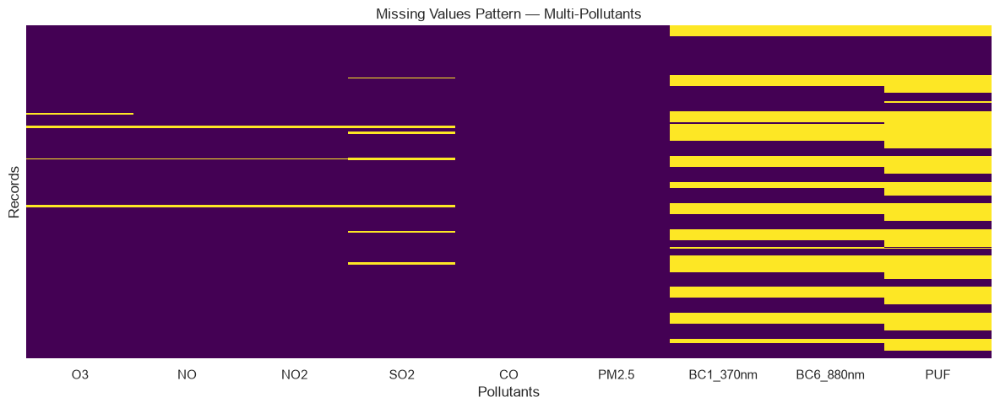

In [27]:
# Missing values heatmap — Multi-Pollutants

plt.figure(figsize=(12, 5))

sns.heatmap(
    multi_combined[
        ['O3', 'NO', 'NO2', 'SO2', 'CO', 'PM2.5',
         'BC1_370nm', 'BC6_880nm', 'PUF']
    ].isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Pattern — Multi-Pollutants")
plt.xlabel("Pollutants")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

In [28]:
# Date and time consistency

print("AQI date and time")
print("-" * 60)

print("Date range:")
print(aqi_combined["date"].min(), "→", aqi_combined["date"].max())

print("\nMissing dates:", aqi_combined["date"].isna().sum())

print("\nHour range:")
print(aqi_combined["heure"].min(), "→", aqi_combined["heure"].max())

print("\nInvalid hours:")
print(
    (~aqi_combined["heure"].between(0, 23)).sum()
)


print("\nMulti-Pollutants date and time")
print("-" * 60)

print("Date range:")
print(
    multi_combined["date_heure"].min(),
    "→",
    multi_combined["date_heure"].max()
)

print("\nMissing date-time:", multi_combined["date_heure"].isna().sum())

AQI date and time
------------------------------------------------------------
Date range:
2013-01-01 00:00:00 → 2026-01-18 00:00:00

Missing dates: 0

Hour range:
0 → 23

Invalid hours:
0

Multi-Pollutants date and time
------------------------------------------------------------
Date range:
2013-01-01 01:00:00 → 2025-12-12 23:00:00

Missing date-time: 1068841


In [29]:
# Date-time validity by year

print("AQI records by year")
print("-" * 60)

aqi_by_year = (
    aqi_combined["date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print(aqi_by_year)


print("\nMulti-Pollutants records by year")
print("-" * 60)

multi_date_check = multi_combined.copy()
multi_date_check["date_year"] = multi_date_check["date_heure"].dt.year

multi_by_year = (
    multi_date_check
    .groupby("year")
    .agg(
        total_records=("year", "size"),
        valid_datetime=("date_heure", "count"),
        invalid_datetime=("date_heure", lambda x: x.isna().sum())
    )
)

multi_by_year["invalid_%"] = (
    multi_by_year["invalid_datetime"]
    / multi_by_year["total_records"]
    * 100
).round(2)

print(multi_by_year)

AQI records by year
------------------------------------------------------------
date
2013    321803
2014    331956
2015    309880
2016    340652
2017    336530
2018    340829
2019    326292
2020    345628
2021    353062
2022    339380
2023    331995
2024    330333
2025    318929
2026     15325
Name: count, dtype: int64

Multi-Pollutants records by year
------------------------------------------------------------
      total_records  valid_datetime  invalid_datetime  invalid_%
year                                                            
2013         105408           39744             65664      62.30
2014          96648               0             96648     100.00
2015          96360               0             96360     100.00
2016          96624               0             96624     100.00
2017          96360               0             96360     100.00
2018          96360               0             96360     100.00
2019          87600               0             87600     100.0

In [30]:
# Inspect original date-time columns

for year in ["2013", "2014", "2015"]:
    df = multi_data[f"rsqa-multi-polluants{year}.csv"]

    print(f"\n{year}")
    print("-" * 60)

    date_columns = [
        col for col in df.columns
        if "DATE" in col.upper() or "HEURE" in col.upper()
    ]

    print("Date/time columns:", date_columns)

    display(df[date_columns].head(10))


2013
------------------------------------------------------------
Date/time columns: ['DATE_HEURE']


,DATE_HEURE
0,01-01-2013 01:00
1,01-01-2013 02:00
2,01-01-2013 03:00
3,01-01-2013 04:00
4,01-01-2013 05:00
5,01-01-2013 06:00
6,01-01-2013 07:00
7,01-01-2013 08:00
8,01-01-2013 09:00
9,01-01-2013 10:00



2014
------------------------------------------------------------
Date/time columns: ['Date', 'heure']


,Date,heure
0,2014-01-01,1:00
1,2014-01-01,2:00
2,2014-01-01,3:00
3,2014-01-01,4:00
4,2014-01-01,5:00
5,2014-01-01,6:00
6,2014-01-01,7:00
7,2014-01-01,8:00
8,2014-01-01,9:00
9,2014-01-01,10:00



2015
------------------------------------------------------------
Date/time columns: ['DATE_ HEURE']


,DATE_ HEURE
0,2015-01-01 01:00
1,2015-01-01 02:00
2,2015-01-01 03:00
3,2015-01-01 04:00
4,2015-01-01 05:00
5,2015-01-01 06:00
6,2015-01-01 07:00
7,2015-01-01 08:00
8,2015-01-01 09:00
9,2015-01-01 10:00


In [31]:
# Inspect raw date-time values

for year in ["2013", "2014", "2015", "2020", "2025"]:
    df = multi_data[f"rsqa-multi-polluants{year}.csv"]

    print(f"\n{year}")
    print("-" * 60)

    date_columns = [
        col for col in df.columns
        if "DATE" in col.upper() or "HEURE" in col.upper()
    ]

    for col in date_columns:
        print(f"\n{col}:")
        print(df[col].head(10).tolist())


2013
------------------------------------------------------------

DATE_HEURE:
['01-01-2013 01:00', '01-01-2013 02:00', '01-01-2013 03:00', '01-01-2013 04:00', '01-01-2013 05:00', '01-01-2013 06:00', '01-01-2013 07:00', '01-01-2013 08:00', '01-01-2013 09:00', '01-01-2013 10:00']

2014
------------------------------------------------------------

Date:
['2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01', '2014-01-01']

heure:
['1:00', '2:00', '3:00', '4:00', '5:00', '6:00', '7:00', '8:00', '9:00', '10:00']

2015
------------------------------------------------------------

DATE_ HEURE:
['2015-01-01 01:00', '2015-01-01 02:00', '2015-01-01 03:00', '2015-01-01 04:00', '2015-01-01 05:00', '2015-01-01 06:00', '2015-01-01 07:00', '2015-01-01 08:00', '2015-01-01 09:00', '2015-01-01 10:00']

2020
------------------------------------------------------------

DATE_HEURE:
['2020-01-01 01:00', '2020-01-01 02:00', '2020-01-01

In [40]:
# Definitive Multi-Pollutants date-time conversion

multi_cleaned = []

for name, df in multi_data.items():
    temp = df.copy()

    year = int(
        name.replace("rsqa-multi-polluants", "").replace(".csv", "")
    )

    # Station
    if "NUMERO_STATION" in temp.columns:
        temp = temp.rename(columns={"NUMERO_STATION": "station_id"})

    if "NO_POSTE" in temp.columns:
        temp = temp.rename(columns={"NO_POSTE": "station_id"})

    # PM2.5
    if "PM2,5" in temp.columns:
        temp = temp.rename(columns={"PM2,5": "PM2.5"})

    # Build raw date-time
    if "Date" in temp.columns and "heure" in temp.columns:

        dates = temp["Date"].astype(str).str.strip()
        hours = temp["heure"].astype(str).str.strip()

        is_2400 = hours.eq("24:00")

        hours_adjusted = hours.where(
            ~is_2400,
            "00:00"
        )

        date_heure = dates + " " + hours_adjusted

        parsed = pd.to_datetime(
            date_heure,
            format="%Y-%m-%d %H:%M",
            errors="coerce"
        )

        parsed.loc[is_2400] += pd.Timedelta(days=1)

        temp["date_heure"] = parsed

        temp = temp.drop(columns=["Date", "heure"])

    else:

        date_column = (
            "DATE_ HEURE"
            if "DATE_ HEURE" in temp.columns
            else "DATE_HEURE"
        )

        raw = temp[date_column].astype(str).str.strip()

        is_2400 = raw.str.endswith("24:00")

        raw_adjusted = raw.str.replace(
            " 24:00",
            " 00:00",
            regex=False
        )

        # Detect date format from the raw value
        iso_format = raw_adjusted.str.match(r"^\d{4}-\d{2}-\d{2}")

        parsed = pd.Series(
            pd.NaT,
            index=temp.index,
            dtype="datetime64[ns]"
        )

        parsed.loc[iso_format] = pd.to_datetime(
            raw_adjusted.loc[iso_format],
            format="%Y-%m-%d %H:%M",
            errors="coerce"
        )

        parsed.loc[~iso_format] = pd.to_datetime(
            raw_adjusted.loc[~iso_format],
            format="%d-%m-%Y %H:%M",
            errors="coerce"
        )

        parsed.loc[is_2400] += pd.Timedelta(days=1)

        temp["date_heure"] = parsed

        temp = temp.drop(columns=[date_column])

    # Standardize names
    if "pst" in temp.columns:
        temp = temp.rename(columns={"pst": "PST"})

    if "pm10" in temp.columns:
        temp = temp.rename(columns={"pm10": "PM10"})

    temp["year"] = year
    temp["source_file"] = name

    multi_cleaned.append(temp)

multi_combined = pd.concat(
    multi_cleaned,
    ignore_index=True,
    sort=False
)

multi_combined = multi_combined.sort_values(
    ["date_heure", "station_id"]
).reset_index(drop=True)

print("Multi-Pollutants dataset")
print("-" * 60)
print("Rows:", f"{len(multi_combined):,}")
print("Columns:", len(multi_combined.columns))
print("Missing date-time:", multi_combined["date_heure"].isna().sum())

Multi-Pollutants dataset
------------------------------------------------------------
Rows: 1,254,313
Columns: 22
Missing date-time: 1103


In [41]:
# Date-time validity by year

multi_date_check = (
    multi_combined
    .groupby("year")
    .agg(
        total_records=("year", "size"),
        valid_datetime=("date_heure", "count"),
        invalid_datetime=("date_heure", lambda x: x.isna().sum())
    )
)

multi_date_check["invalid_%"] = (
    multi_date_check["invalid_datetime"]
    / multi_date_check["total_records"]
    * 100
).round(2)

print(multi_date_check)

      total_records  valid_datetime  invalid_datetime  invalid_%
year                                                            
2013         105408          105120               288       0.27
2014          96648           96360               288       0.30
2015          96360           96360                 0       0.00
2016          96624           96624                 0       0.00
2017          96360           96360                 0       0.00
2018          96360           96360                 0       0.00
2019          87600           87600                 0       0.00
2020          96624           96624                 0       0.00
2021          96360           96360                 0       0.00
2022          96624           96360               264       0.27
2023          96624           96361               263       0.27
2024          96361           96361                 0       0.00
2025          96360           96360                 0       0.00


In [42]:
# Data types consistency

print("AQI data types")
print(aqi_combined.dtypes)

print("\nMulti-Pollutants data types")
print(multi_combined.dtypes)

AQI data types
stationId               int64
polluant                  str
valeur                  int64
date           datetime64[us]
heure                   int64
source_file               str
period                    str
dtype: object

Multi-Pollutants data types
station_id             float64
CO                         str
NO                      object
NO2                     object
PM2.5                   object
O3                      object
SO2                     object
PM10                       str
PST                        str
Benzene                 object
Toluene                 object
Ethylbenzene            object
MP-Xylene               object
O-Xylene                object
date_heure      datetime64[ns]
year                     int64
source_file                str
BC1_370nm                  str
BC6_880nm                  str
site                       str
H2S                        str
PUF                        str
dtype: object


In [43]:
# Special values in Multi-Pollutants

special_values = {}

for column in multi_combined.columns:
    count_nm = multi_combined[column].astype(str).str.strip().eq("N/M").sum()
    if count_nm > 0:
        special_values[column] = count_nm

special_values = pd.Series(special_values).sort_values(ascending=False)

print("N/M values by column")
print(special_values)

N/M values by column
Benzene         973392
Toluene         973392
O-Xylene        973392
MP-Xylene       973392
Ethylbenzene    973392
CO              736946
BC1_370nm       692546
BC6_880nm       692546
SO2             649080
PM10            631465
PST             631465
H2S             420745
PUF             411986
O3              175824
NO              132000
NO2             132000
PM2.5            44616
dtype: int64


In [44]:
# N/M values by year

pollutant_columns = [
    "CO", "NO", "NO2", "PM2.5", "O3", "SO2",
    "PM10", "PST", "Benzene", "Toluene",
    "Ethylbenzene", "MP-Xylene", "O-Xylene",
    "BC1_370nm", "BC6_880nm", "H2S", "PUF"
]

nm_by_year = (
    multi_combined
    .groupby("year")[pollutant_columns]
    .apply(lambda x: x.astype(str).apply(lambda col: col.str.strip().eq("N/M").sum()))
)

print(nm_by_year)

         CO     NO    NO2  PM2.5     O3    SO2   PM10    PST  Benzene  \
year                                                                    
2013  61608  26568  26568  17808  35328  61608  87888  87888    96648   
2014  52824      0      0   9024      0      0  79104  79104        0   
2015  52560  17520  17520   8760  26280  52560      0      0    87600   
2016  52704   8784   8784      0  17568  52704      0      0    87840   
2017  52560   8760   8760      0  17520  52560      0      0    87600   
2018  52560   8760   8760   8760  17520  52560  61320  61320    87600   
2019  43800   8760   8760      0   8760  52560  52560  52560    78840   
2020  52704   8784   8784      0   8784  52704  70272  70272    87840   
2021  52560   8760   8760      0   8760  52560  87600  87600    96360   
2022  52824   9024   9024    264   9024  52824      0      0    87864   
2023  70081   8760   8760      0   8760  52560      0      0    87600   
2024  70081   8760   8760      0   8760  52560  963

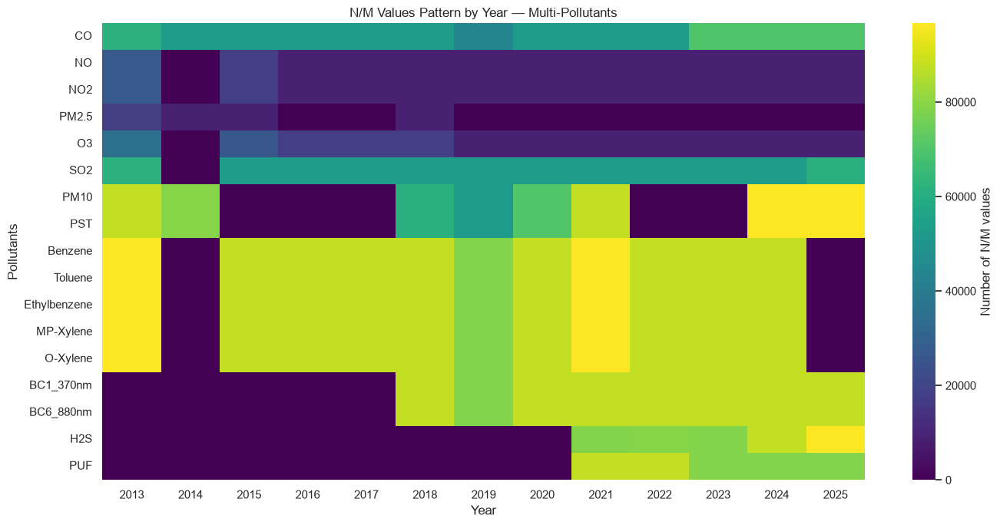

In [47]:
# Multi-Pollutants heatmap of N/M for year values
plt.figure(figsize=(14, 7))

sns.heatmap(
    nm_by_year[pollutant_columns].T,
    cmap="viridis",
    cbar_kws={"label": "Number of N/M values"}
)

plt.title("N/M Values Pattern by Year — Multi-Pollutants")
plt.xlabel("Year")
plt.ylabel("Pollutants")
plt.tight_layout()
plt.show()

Both datasets were inspected for structure, data types, missing values, duplicates, and temporal consistency.

The AQI dataset contains no missing or duplicated records. The Multi-Pollutants dataset contains missing values and `N/M` entries that vary by pollutant and year. These values were identified but not removed, as they may reflect differences in data availability.

Date-time formats were standardized and invalid dates were identified for treatment during the data preparation stage.


--- 
### Non-measurement Values

The source files contain several codes that indicate that a value is not a valid measurement:

* **`alarm`, `down`, `InVld`**: equipment malfunction, intervention, or invalid data.
* **`span`, `calib`, `purge`, `zero`**: calibration or zeroing procedures.
* **`<Samp`**: insufficient data to validate the hourly measurement.
* **`No Data`, `RS232`, `FailPwr`**: communication or power failure.
* **`N/M` or empty values**: not measured.
* **`N/A`**: not available.

These values will be handled during data preparation rather than being removed automatically.

---

## 1.3 Data Preparation — Standardize non-measurement values

In [48]:
# Standardize non-measurement values

non_measurement_values = [
    "alarm", "down", "<Samp", "span", "calib",
    "purge", "InVld", "zero", "No Data",
    "RS232", "FailPwr", "N/M", "N/A", ""
]

for column in pollutant_columns:
    multi_combined[column] = (
        multi_combined[column]
        .astype(str)
        .str.strip()
        .replace(non_measurement_values, np.nan)
    )

    multi_combined[column] = pd.to_numeric(
        multi_combined[column],
        errors="coerce"
    )

print(multi_combined[pollutant_columns].dtypes)

CO              float64
NO              float64
NO2             float64
PM2.5           float64
O3              float64
SO2             float64
PM10            float64
PST             float64
Benzene         float64
Toluene         float64
Ethylbenzene    float64
MP-Xylene       float64
O-Xylene        float64
BC1_370nm       float64
BC6_880nm       float64
H2S             float64
PUF             float64
dtype: object


In [49]:
# Validate data preparation

print("Rows:", f"{len(multi_combined):,}")

print("\nMissing values after standardization")
print(
    multi_combined[pollutant_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Rows: 1,254,313

Missing values after standardization
H2S             1200875
PUF             1194612
BC1_370nm       1190190
BC6_880nm       1189504
O-Xylene        1183577
Toluene         1183203
MP-Xylene       1183202
Ethylbenzene    1183202
Benzene         1183202
PM10            1142523
PST             1142522
CO               803925
SO2              718826
O3               239844
NO               208827
NO2              208819
PM2.5             93977
dtype: int64


In [50]:
# Prepare AQI temporal variables

aqi_combined["year"] = aqi_combined["date"].dt.year
aqi_combined["month"] = aqi_combined["date"].dt.month
aqi_combined["day"] = aqi_combined["date"].dt.day

print(aqi_combined[["date", "heure", "year", "month", "day"]].head())

        date  heure  year  month  day
0 2013-08-05      3  2013      8    5
1 2013-08-05      3  2013      8    5
2 2013-08-05      4  2013      8    5
3 2013-08-05      4  2013      8    5
4 2013-08-05      4  2013      8    5


In [51]:
# Prepare Multi-Pollutants temporal variables

multi_combined["year"] = multi_combined["date_heure"].dt.year
multi_combined["month"] = multi_combined["date_heure"].dt.month
multi_combined["day"] = multi_combined["date_heure"].dt.day
multi_combined["hour"] = multi_combined["date_heure"].dt.hour

print(
    multi_combined[
        ["date_heure", "year", "month", "day", "hour"]
    ].head()
)

           date_heure    year  month  day  hour
0 2013-01-01 01:00:00  2013.0    1.0  1.0   1.0
1 2013-01-01 01:00:00  2013.0    1.0  1.0   1.0
2 2013-01-01 01:00:00  2013.0    1.0  1.0   1.0
3 2013-01-01 01:00:00  2013.0    1.0  1.0   1.0
4 2013-01-01 01:00:00  2013.0    1.0  1.0   1.0


In [52]:
# Final Data Preparation validation

print("AQI")
print("-" * 40)
print("Rows:", f"{len(aqi_combined):,}")
print("Missing dates:", aqi_combined["date"].isna().sum())

print("\nMulti-Pollutants")
print("-" * 40)
print("Rows:", f"{len(multi_combined):,}")
print("Missing date-time:", multi_combined["date_heure"].isna().sum())

print("\nExpected rows preserved:")
print("AQI: 4,342,594")
print("Multi-Pollutants: 1,254,313")

AQI
----------------------------------------
Rows: 4,342,594
Missing dates: 0

Multi-Pollutants
----------------------------------------
Rows: 1,254,313
Missing date-time: 1103

Expected rows preserved:
AQI: 4,342,594
Multi-Pollutants: 1,254,313


The data preparation standardized pollutant values, converted non-measurement codes to missing values, and created temporal variables for both datasets.

All original records were preserved. The AQI dataset contains no missing dates, while the Multi-Pollutants dataset retains 1,103 records with invalid date-time values for further treatment if required.

## 1.4 AQI Analysis

In [53]:
# Distribution of AQI records by pollutant

aqi_combined["polluant"].value_counts()

polluant
PM     1178506
NO2    1073010
O3     1041102
SO2     549225
CO      500751
Name: count, dtype: int64

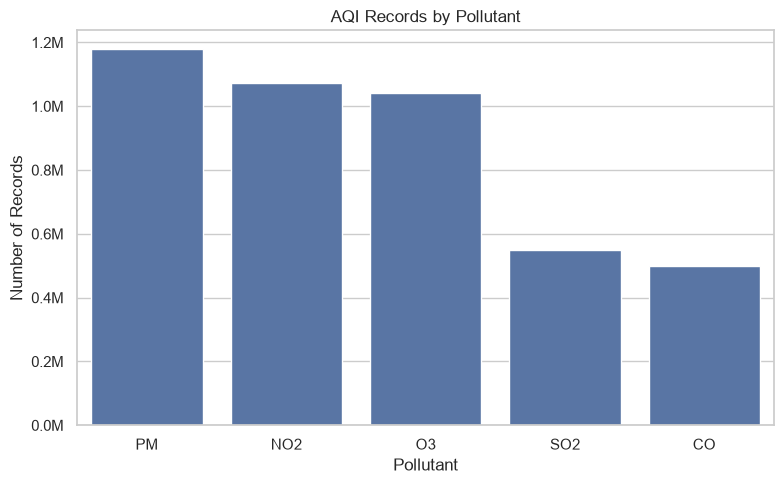

In [55]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=aqi_combined,
    x="polluant",
    order=aqi_combined["polluant"].value_counts().index
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M")
)

plt.title("AQI Records by Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [56]:
# AQI value distribution by pollutant

aqi_combined.groupby("polluant")["valeur"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
polluant,,,,,,,,
CO,500751.0,1.01,0.11,0.0,1.0,1.0,1.0,9.0
NO2,1073010.0,2.61,1.83,0.0,1.0,2.0,3.0,28.0
O3,1041102.0,15.32,7.09,0.0,10.0,15.0,20.0,54.0
PM,1178506.0,11.67,9.88,0.0,6.0,9.0,15.0,484.0
SO2,549225.0,1.05,0.91,0.0,1.0,1.0,1.0,45.0


### Initial Observations

The AQI dataset contains five pollutants with different numbers of observations and value distributions. PM has the highest number of records, followed by NO2 and O3, while CO and SO2 have fewer observations.

The descriptive statistics also show differences in the average and range of AQI values between pollutants. These differences will be explored further in the following analyses.

In [58]:
# Number of measurements by pollutant

multi_combined[pollutant_columns].count().sort_values(ascending=False)

PM2.5           1160336
NO2             1045494
NO              1045486
O3              1014469
SO2              535487
CO               450388
PST              111791
PM10             111790
Ethylbenzene      71111
MP-Xylene         71111
Benzene           71111
Toluene           71110
O-Xylene          70736
BC6_880nm         64809
BC1_370nm         64123
PUF               59701
H2S               53438
dtype: int64

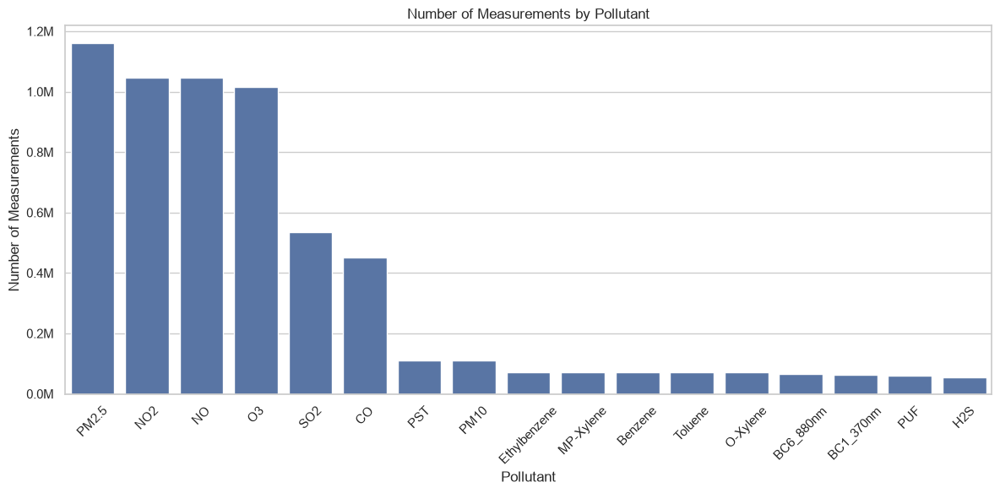

In [59]:
# Distribution of measurements by pollutant

measurement_counts = (
    multi_combined[pollutant_columns]
    .count()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=measurement_counts.index,
    y=measurement_counts.values
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M")
)

plt.title("Number of Measurements by Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("Number of Measurements")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
# Descriptive statistics by pollutant

multi_combined[pollutant_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CO,450388.0,226.12,102.80,0.00,160.92,198.41,259.42,5328.39
NO,1045486.0,3.51,8.22,0.00,0.22,0.94,3.17,414.51
NO2,1045494.0,8.90,7.67,0.00,3.50,6.57,11.95,116.75
PM2.5,1160336.0,7.83,7.32,0.00,3.56,6.00,9.98,976.27
O3,1014469.0,24.26,11.63,0.00,16.14,24.31,31.97,263.20
SO2,535487.0,0.64,1.76,0.00,0.02,0.19,0.60,104.11
PM10,111790.0,20.79,28.85,0.07,7.81,13.96,24.13,1386.01
PST,111791.0,77.36,184.27,0.07,13.23,29.99,73.28,5980.42
Benzene,71111.0,1.19,2.93,0.00,0.20,0.46,1.10,171.30
Toluene,71110.0,2.17,4.26,0.00,0.47,1.12,2.34,188.60


### Initial Observations

The Multi-Pollutants dataset contains different numbers of measurements depending on the pollutant. PM2.5, NO2, NO, and O3 have the highest number of observations, while H2S, PUF, and the aromatic compounds have fewer measurements.

The descriptive statistics also show substantial differences in the distributions and scales of the pollutants. These differences will be considered when comparing pollutant concentrations in the following analyses.

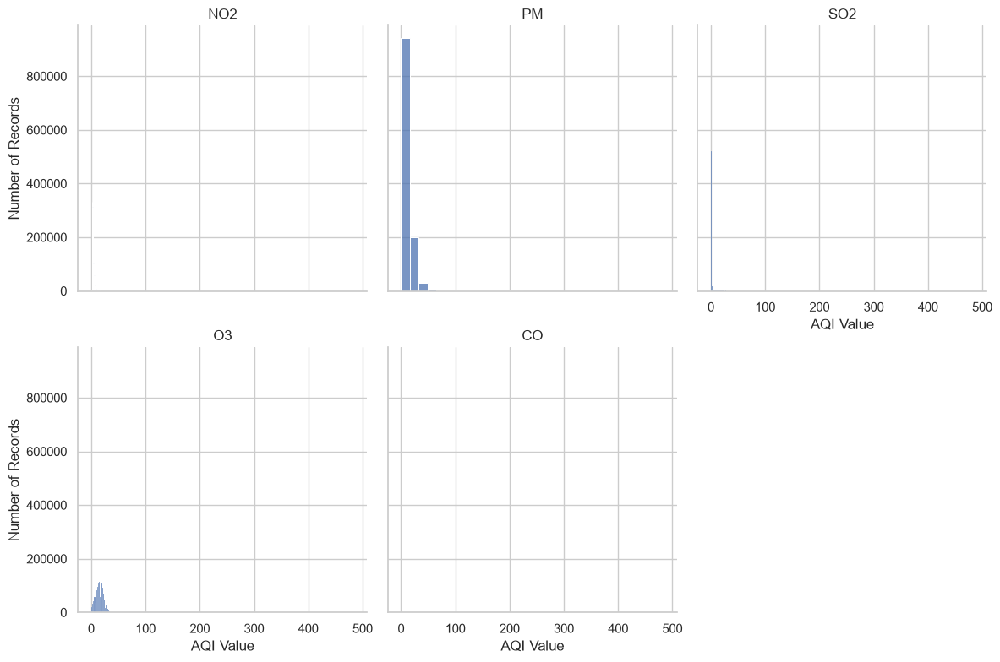

In [62]:
# AQI distribution by pollutant

g = sns.FacetGrid(
    aqi_combined,
    col="polluant",
    col_wrap=3,
    height=4
)

g.map_dataframe(
    sns.histplot,
    x="valeur",
    bins=30
)

g.set_axis_labels("AQI Value", "Number of Records")
g.set_titles("{col_name}")

plt.tight_layout()
plt.show()

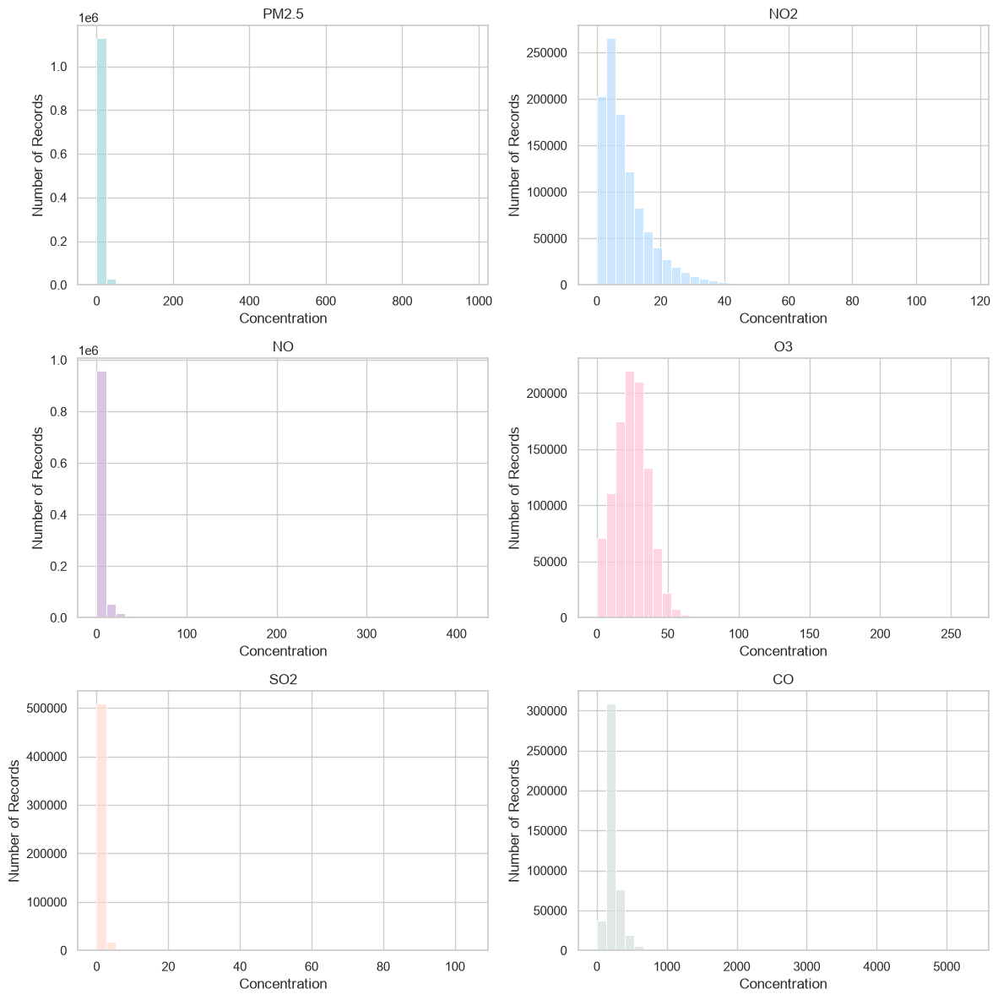

In [65]:
# Main pollutant distributions

main_pollutants = [
    "PM2.5", "NO2", "NO", "O3", "SO2", "CO"
]

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2",
    "#D8E2DC"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 12)
)

for ax, pollutant, color in zip(
    axes.flat,
    main_pollutants,
    pastel_colors
):
    sns.histplot(
        multi_combined[pollutant].dropna(),
        bins=40,
        ax=ax,
        color=color
    )

    ax.set_title(pollutant)
    ax.set_xlabel("Concentration")
    ax.set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [66]:
# AQI records by year

aqi_by_year = (
    aqi_combined
    .groupby("year")
    .size()
)

print(aqi_by_year)

year
2013    321803
2014    331956
2015    309880
2016    340652
2017    336530
2018    340829
2019    326292
2020    345628
2021    353062
2022    339380
2023    331995
2024    330333
2025    318929
2026     15325
dtype: int64


/var/folders/4j/hdmx1pgn4_58dhjydqrp6xw00000gn/T/ipykernel_80253/4050265972.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


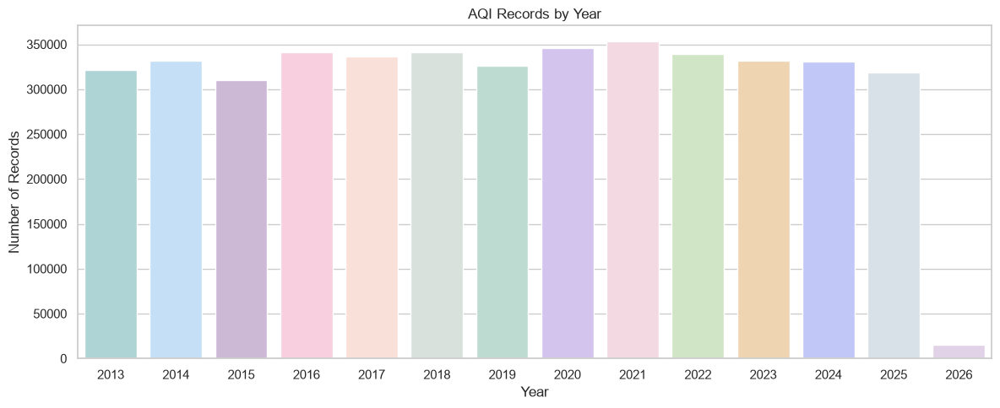

In [70]:
# AQI records by year

aqi_by_year = (
    aqi_combined
    .groupby("year")
    .size()
)

pastel_colors = [
    "#A8DADC", "#BDE0FE", "#CDB4DB", "#FFC8DD",
    "#FFDDD2", "#D8E2DC", "#B8E0D2", "#D0BDF4",
    "#F7D6E0", "#CDEAC0", "#F9D5A7", "#B8C0FF",
    "#D6E2E9", "#E2CFEA"
]

plt.figure(figsize=(12, 5))

sns.barplot(
    x=aqi_by_year.index.astype(str),
    y=aqi_by_year.values,
    palette=pastel_colors
)

plt.title("AQI Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [68]:
# Multi-Pollutants records by year

multi_by_year = (
    multi_combined
    .groupby("year")
    .size()
)

print(multi_by_year)

year
2013.0    105108
2014.0     96372
2015.0     96360
2016.0     96624
2017.0     96360
2018.0     96360
2019.0     87600
2020.0     96624
2021.0     96360
2022.0     96349
2023.0     96361
2024.0     96361
2025.0     96360
2026.0        11
dtype: int64


/var/folders/4j/hdmx1pgn4_58dhjydqrp6xw00000gn/T/ipykernel_80253/2165168319.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


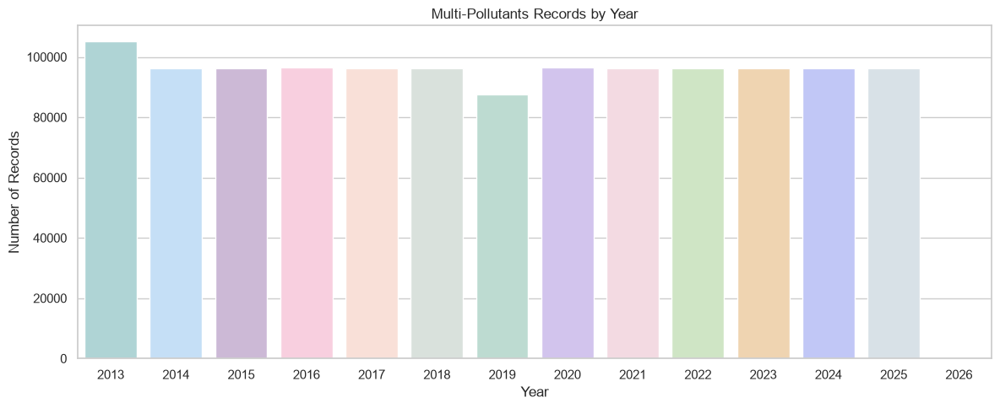

In [72]:
# Multi-Pollutants records by year

multi_by_year = (
    multi_combined
    .groupby("year")
    .size()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=multi_by_year.index.astype(int).astype(str),
    y=multi_by_year.values,
    palette=pastel_colors
)

plt.title("Multi-Pollutants Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

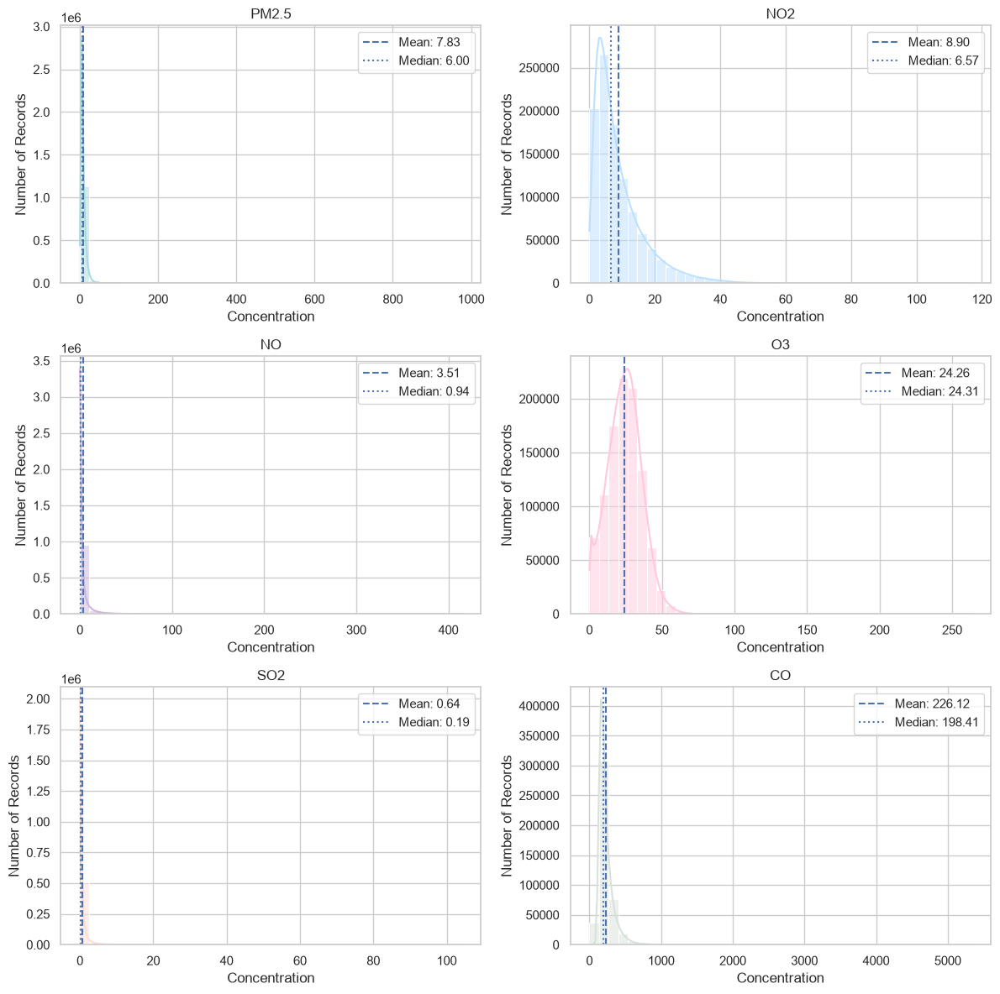

In [73]:
# Histograms with KDE, mean, and median

main_pollutants = [
    "PM2.5", "NO2", "NO", "O3", "SO2", "CO"
]

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2",
    "#D8E2DC"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 12)
)

for ax, pollutant, color in zip(
    axes.flat,
    main_pollutants,
    pastel_colors
):
    data = multi_combined[pollutant].dropna()

    sns.histplot(
        data,
        bins=40,
        kde=True,
        ax=ax,
        color=color
    )

    mean = data.mean()
    median = data.median()

    ax.axvline(
        mean,
        linestyle="--",
        label=f"Mean: {mean:.2f}"
    )

    ax.axvline(
        median,
        linestyle=":",
        label=f"Median: {median:.2f}"
    )

    ax.set_title(pollutant)
    ax.set_xlabel("Concentration")
    ax.set_ylabel("Number of Records")
    ax.legend()

plt.tight_layout()
plt.show()

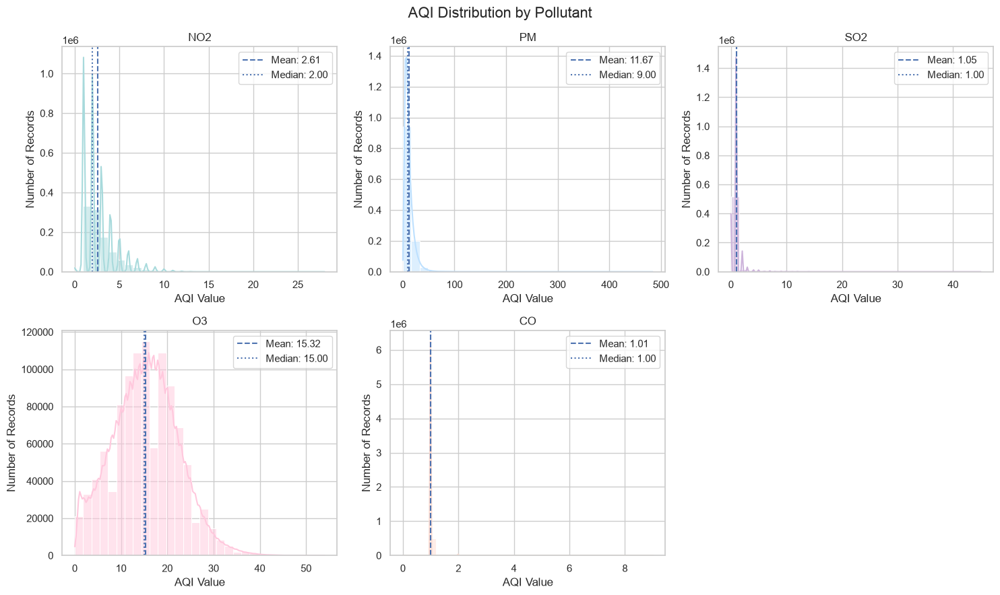

In [74]:
# AQI histograms with KDE, mean, and median

pollutants = aqi_combined["polluant"].unique()

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax, pollutant, color in zip(
    axes.flat,
    pollutants,
    pastel_colors
):
    data = aqi_combined.loc[
        aqi_combined["polluant"] == pollutant,
        "valeur"
    ].dropna()

    sns.histplot(
        data,
        bins=30,
        kde=True,
        ax=ax,
        color=color
    )

    mean = data.mean()
    median = data.median()

    ax.axvline(
        mean,
        linestyle="--",
        label=f"Mean: {mean:.2f}"
    )

    ax.axvline(
        median,
        linestyle=":",
        label=f"Median: {median:.2f}"
    )

    ax.set_title(pollutant)
    ax.set_xlabel("AQI Value")
    ax.set_ylabel("Number of Records")
    ax.legend()

# Remove unused subplot
axes.flat[-1].remove()

plt.suptitle(
    "AQI Distribution by Pollutant",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Distribution Observations

The histograms show different distribution patterns across pollutants in both datasets. In several cases, the mean and median are not aligned, indicating asymmetric distributions.

Most observations are concentrated at lower values, while some pollutants show a wider spread. These patterns will be further examined through outlier detection and correlation analysis.

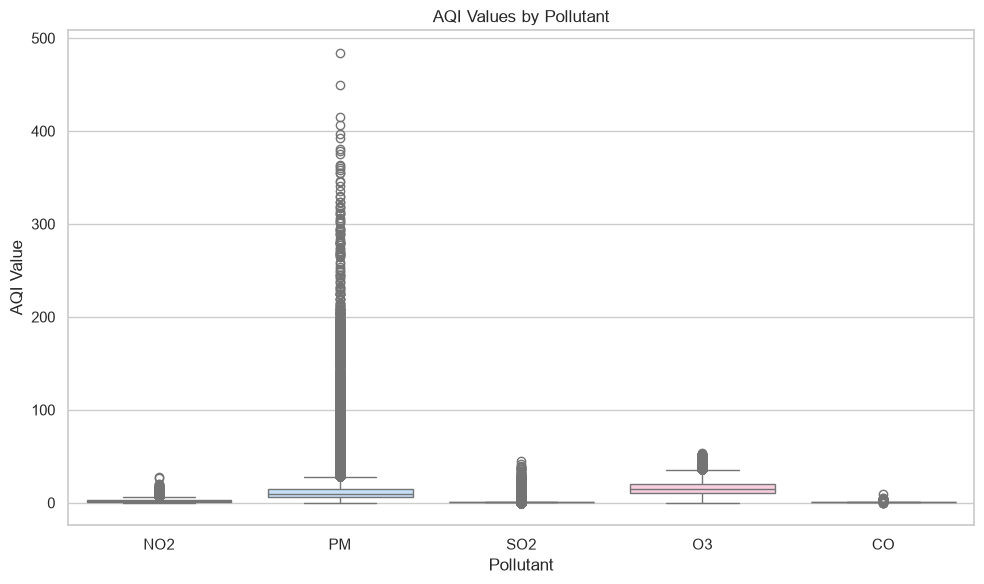

AQI Outlier Values
----------------------------------------
Pollutant  AQI Value
      NO2          7
      NO2          7
      NO2          7
      NO2          7
      NO2          7
      NO2          7
      NO2          8
      NO2          7
      NO2          7
      NO2          9
      NO2          8
      NO2          8
      NO2          7
      NO2          7
      NO2          8
      NO2          8
      NO2          7
      NO2          8
      NO2          8
      NO2          7
      NO2          8
      NO2          8
      NO2          8
      NO2         11
      NO2          9
      NO2          8
      NO2          7
      NO2          7
      NO2         10
      NO2         10
      NO2          8
      NO2          9
      NO2          7
      NO2          7
      NO2          8
      NO2          8
      NO2          7
      NO2          7
      NO2          7
      NO2          7
      NO2          7
      NO2          8
      NO2          7
      NO2       

In [80]:
# AQI boxplots for outlier detection

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2"
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=aqi_combined,
    x="polluant",
    y="valeur",
    hue="polluant",
    palette=pastel_colors,
    legend=False
)

plt.title("AQI Values by Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("AQI Value")
plt.tight_layout()
plt.show()


# Calculate and display AQI outliers

aqi_outliers = []

for pollutant in aqi_combined["polluant"].unique():

    data = aqi_combined.loc[
        aqi_combined["polluant"] == pollutant,
        "valeur"
    ].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    for value in outliers:
        aqi_outliers.append({
            "Pollutant": pollutant,
            "AQI Value": value
        })

aqi_outliers_df = pd.DataFrame(aqi_outliers)

print("AQI Outlier Values")
print("-" * 40)
print(aqi_outliers_df.to_string(index=False))

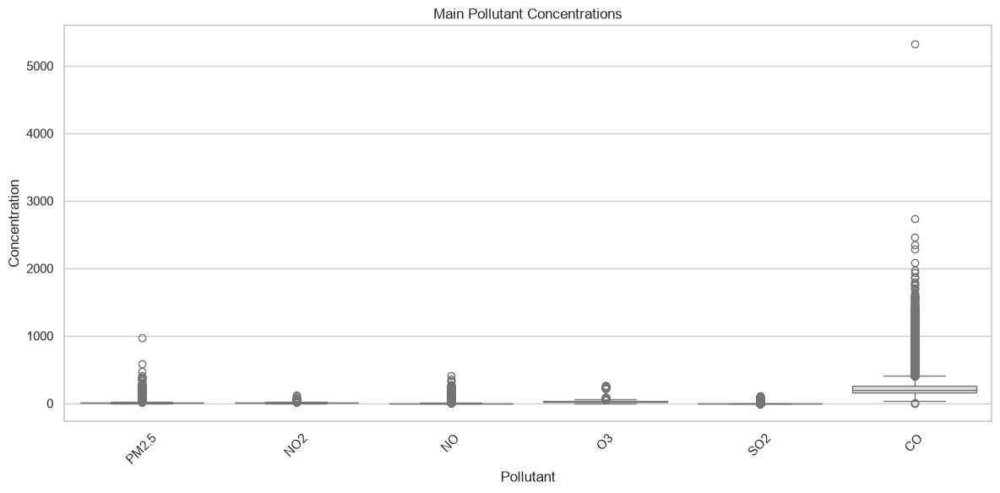

Multi-Pollutants Outlier Values
----------------------------------------
Pollutant  Concentration
    PM2.5      19.624310
    PM2.5      21.200000
    PM2.5      22.300000
    PM2.5      24.700000
    PM2.5      19.900000
    PM2.5      20.500000
    PM2.5      23.671250
    PM2.5      26.100000
    PM2.5      21.900000
    PM2.5      24.100000
    PM2.5      21.700000
    PM2.5      22.752080
    PM2.5      23.700000
    PM2.5      25.700000
    PM2.5      26.900000
    PM2.5      23.400000
    PM2.5      22.600000
    PM2.5      27.400000
    PM2.5      21.229720
    PM2.5      25.400000
    PM2.5      27.400000
    PM2.5      26.000000
    PM2.5      20.800000
    PM2.5      20.900000
    PM2.5      22.600000
    PM2.5      30.400000
    PM2.5      26.800000
    PM2.5      24.400000
    PM2.5      22.800000
    PM2.5      21.300000
    PM2.5      23.400000
    PM2.5      22.700000
    PM2.5      22.900000
    PM2.5      19.711810
    PM2.5      32.200000
    PM2.5      26.700000
  

In [81]:
# Multi-Pollutants boxplots for outlier detection

main_pollutants = [
    "PM2.5", "NO2", "NO", "O3", "SO2", "CO"
]

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2",
    "#D8E2DC"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=multi_combined[main_pollutants],
    hue=None,
    palette=pastel_colors
)

plt.title("Main Pollutant Concentrations")
plt.xlabel("Pollutant")
plt.ylabel("Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Calculate and display Multi-Pollutants outliers

multi_outliers = []

for pollutant in main_pollutants:

    data = multi_combined[pollutant].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    for value in outliers:
        multi_outliers.append({
            "Pollutant": pollutant,
            "Concentration": value
        })

multi_outliers_df = pd.DataFrame(multi_outliers)

print("Multi-Pollutants Outlier Values")
print("-" * 40)
print(multi_outliers_df.to_string(index=False))

### Outlier Observations

The boxplots show the presence of outliers in both datasets. In the AQI dataset, several outliers are concentrated in specific pollutants and often appear as repeated values.

In the Multi-Pollutants dataset, outliers are also present across the main pollutants, with some measurements reaching considerably higher concentrations than the typical range.

These values were identified using the IQR method and will be retained for further analysis rather than removed automatically.

In [82]:
# Select pollutant columns and calculate correlation

pollutant_columns = [
    "CO", "NO", "NO2", "PM2.5", "O3", "SO2",
    "PM10", "PST", "Benzene", "Toluene",
    "Ethylbenzene", "MP-Xylene", "O-Xylene",
    "BC1_370nm", "BC6_880nm", "H2S", "PUF"
]

correlation_matrix = multi_combined[
    pollutant_columns
].corr()

print("Correlation Matrix")
print("-" * 40)
print(correlation_matrix.round(2))

Correlation Matrix
----------------------------------------
                CO    NO   NO2  PM2.5    O3   SO2  PM10   PST  Benzene  \
CO            1.00  0.61  0.73   0.66 -0.40  0.19  0.34  0.12      NaN   
NO            0.61  1.00  0.61   0.29 -0.38  0.10  0.33  0.23     0.11   
NO2           0.73  0.61  1.00   0.46 -0.54  0.14  0.35  0.17     0.19   
PM2.5         0.66  0.29  0.46   1.00 -0.16  0.09  0.44  0.16     0.08   
O3           -0.40 -0.38 -0.54  -0.16  1.00 -0.04 -0.10  0.03    -0.10   
SO2           0.19  0.10  0.14   0.09 -0.04  1.00   NaN   NaN     0.07   
PM10          0.34  0.33  0.35   0.44 -0.10   NaN  1.00  0.84      NaN   
PST           0.12  0.23  0.17   0.16  0.03   NaN  0.84  1.00      NaN   
Benzene        NaN  0.11  0.19   0.08 -0.10  0.07   NaN   NaN     1.00   
Toluene        NaN  0.17  0.24   0.11 -0.23  0.02   NaN   NaN     0.22   
Ethylbenzene   NaN  0.10  0.13   0.08 -0.10  0.02   NaN   NaN     0.41   
MP-Xylene      NaN  0.09  0.18   0.10 -0.08  0.02   

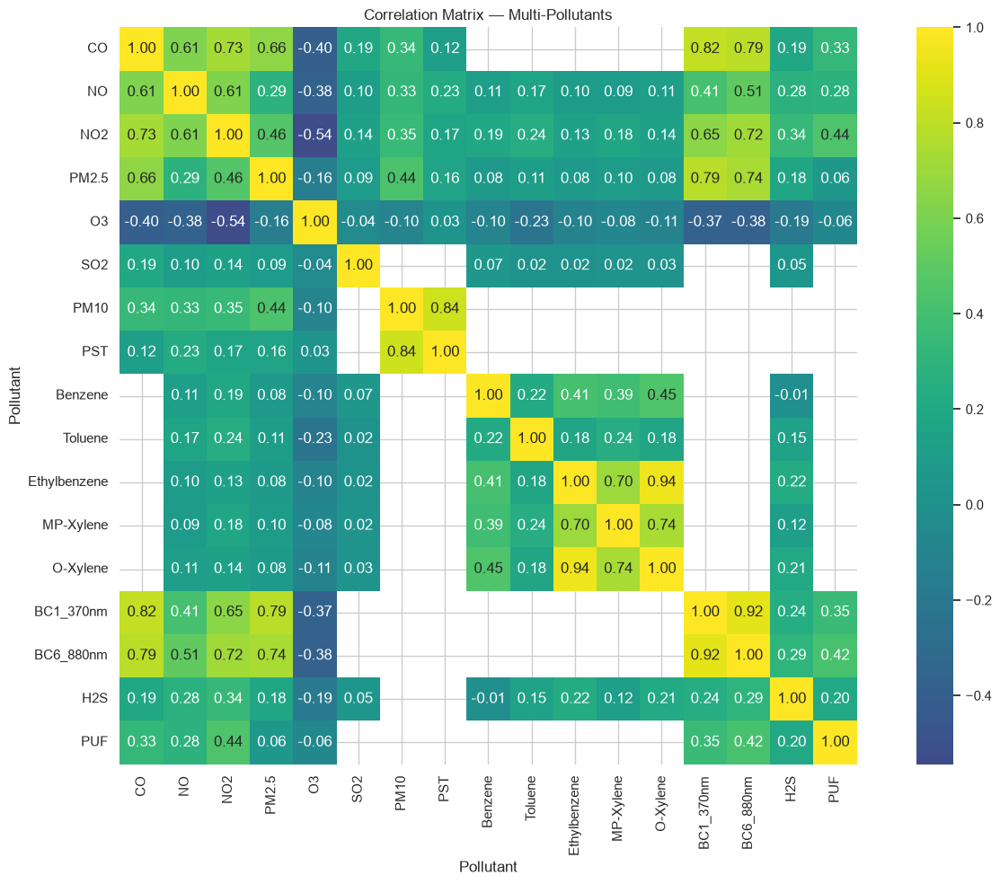

In [83]:
# Correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    center=0,
    square=True
)

plt.title("Correlation Matrix — Multi-Pollutants")
plt.xlabel("Pollutant")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.show()

### Correlation Observations

The correlation matrix shows several notable relationships between pollutants. CO, NO, and NO2 present moderate to strong positive correlations, while O3 shows negative correlations with these pollutants.

PM2.5 is positively correlated with CO, NO2, and BC measurements. PM10 and PST also show a strong positive correlation. The BC1_370nm and BC6_880nm measurements present a particularly strong positive correlation.

Some correlations appear as `NaN` because the corresponding pollutants do not have enough overlapping measurements for the calculation. These differences in data availability should be considered when interpreting the relationships.


---
### Key Correlations

Several relationships stand out in the correlation matrix:

* **CO ↔ NO2:** `0.73`
* **PM10 ↔ PST:** `0.84`
* **BC1_370nm ↔ BC6_880nm:** `0.92`
* **NO2 ↔ O3:** `-0.54`

The first three represent relatively strong positive relationships, while NO2 and O3 show a moderate negative relationship.

The `NaN` values were not removed because they reflect the unequal availability of measurements between pollutants, as identified during the data preparation stage.


In [88]:
aqi_annual_means = (
    aqi_combined[
        aqi_combined["year"].between(2013, 2025)
    ]
    .groupby(["year", "polluant"])["valeur"]
    .mean()
    .unstack()
)

print(aqi_annual_means.round(2))

polluant    CO   NO2     O3     PM   SO2
year                                    
2013      1.03  2.99  14.59  15.08  1.05
2014      1.02  2.90  14.54  13.51  1.15
2015      1.02  2.87  15.04  12.80  1.14
2016      1.01  2.73  14.89  10.52  1.08
2017      1.01  2.72  14.79  11.08  1.08
2018      1.01  2.76  15.72  11.40  1.09
2019      1.00  2.66  15.45  10.82  1.06
2020      1.01  2.42  15.31  10.39  1.02
2021      1.00  2.39  15.39  11.10  1.02
2022      1.01  2.48  15.20  10.70  1.01
2023      1.01  2.36  16.21  12.72  0.92
2024      1.01  2.26  15.66  10.53  0.94
2025      1.01  2.33  16.14  11.67  1.08


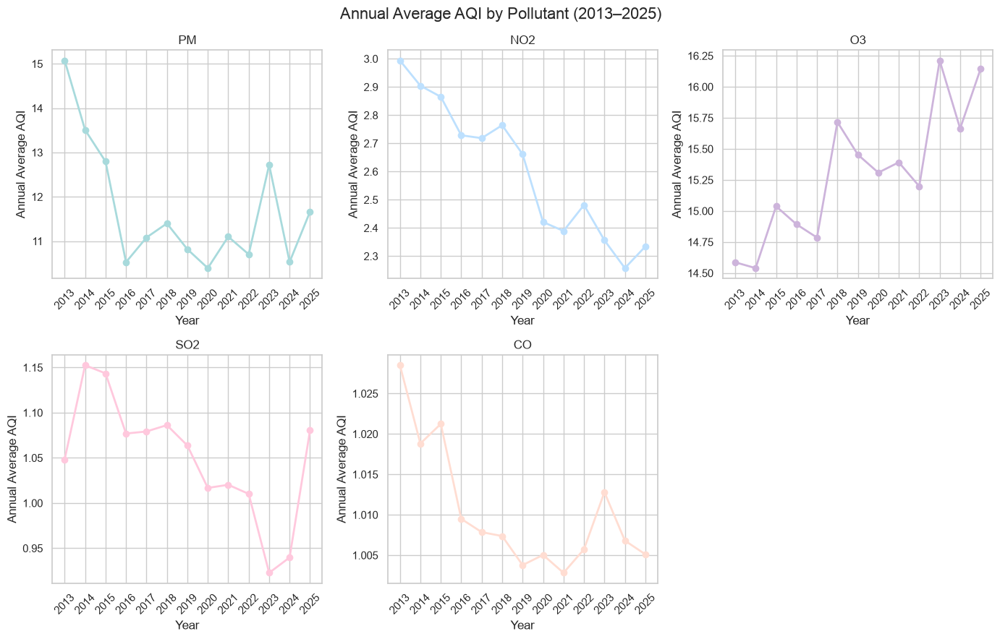

In [89]:
aqi_pollutants = [
    "PM", "NO2", "O3", "SO2", "CO"
]

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 9)
)

for ax, pollutant, color in zip(
    axes.flat,
    aqi_pollutants,
    pastel_colors
):
    ax.plot(
        aqi_annual_means.index,
        aqi_annual_means[pollutant],
        marker="o",
        linewidth=2,
        color=color
    )

    ax.set_title(pollutant)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual Average AQI")
    ax.set_xticks(aqi_annual_means.index)
    ax.tick_params(axis="x", rotation=45)

axes.flat[-1].remove()

plt.suptitle(
    "Annual Average AQI by Pollutant (2013–2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [90]:
aqi_change_2013_2025 = (
    (aqi_annual_means.loc[2025] - aqi_annual_means.loc[2013])
    / aqi_annual_means.loc[2013]
) * 100

print("AQI Percentage Change: 2013 → 2025")
print("-" * 40)
print(aqi_change_2013_2025.round(2))

AQI Percentage Change: 2013 → 2025
----------------------------------------
polluant
CO     -2.27
NO2   -22.04
O3     10.68
PM    -22.62
SO2     3.09
dtype: float64


---
### Annual Trend Observations

The annual AQI averages show different trends among pollutants between 2013 and 2025. NO2 shows a **22.04% decrease**, while PM decreases by **22.62%**. CO remains relatively stable, with a small decrease of **2.27%**.

In contrast, O3 shows a **10.68% increase**, while SO2 increases slightly by **3.09%**. Overall, the AQI results indicate a reduction in the average values of NO2 and PM, while O3 and SO2 follow an opposite trend and CO remains relatively stable.
---

In [84]:
main_pollutants = [
    "PM2.5", "NO2", "NO", "O3", "SO2", "CO"
]

annual_means = (
    multi_combined[
        multi_combined["year"].between(2013, 2025)
    ]
    .groupby("year")[main_pollutants]
    .mean()
)

print(annual_means.round(2))

        PM2.5    NO2    NO     O3   SO2      CO
year                                           
2013.0  10.13  10.67  4.81  23.29  0.97  309.98
2014.0   9.12  10.19  4.46  23.01  1.04  359.40
2015.0   8.64   9.96  4.60  23.74  0.81  257.76
2016.0   7.02   9.39  3.88  23.56  0.75  219.76
2017.0   7.41   9.44  3.63  23.32  0.69  219.01
2018.0   7.79   9.64  3.72  24.84  0.63  215.71
2019.0   7.19   9.07  3.67  24.45  0.50  208.20
2020.0   6.92   8.14  3.11  24.18  0.44  199.56
2021.0   7.43   8.04  2.97  24.31  0.41  211.61
2022.0   7.14   8.42  3.22  24.00  0.43  207.71
2023.0   8.61   7.89  2.60  25.65  0.42  240.46
2024.0   7.04   7.47  2.63  24.70  0.53  223.54
2025.0   7.82   7.81  2.71  25.54  0.73  211.88


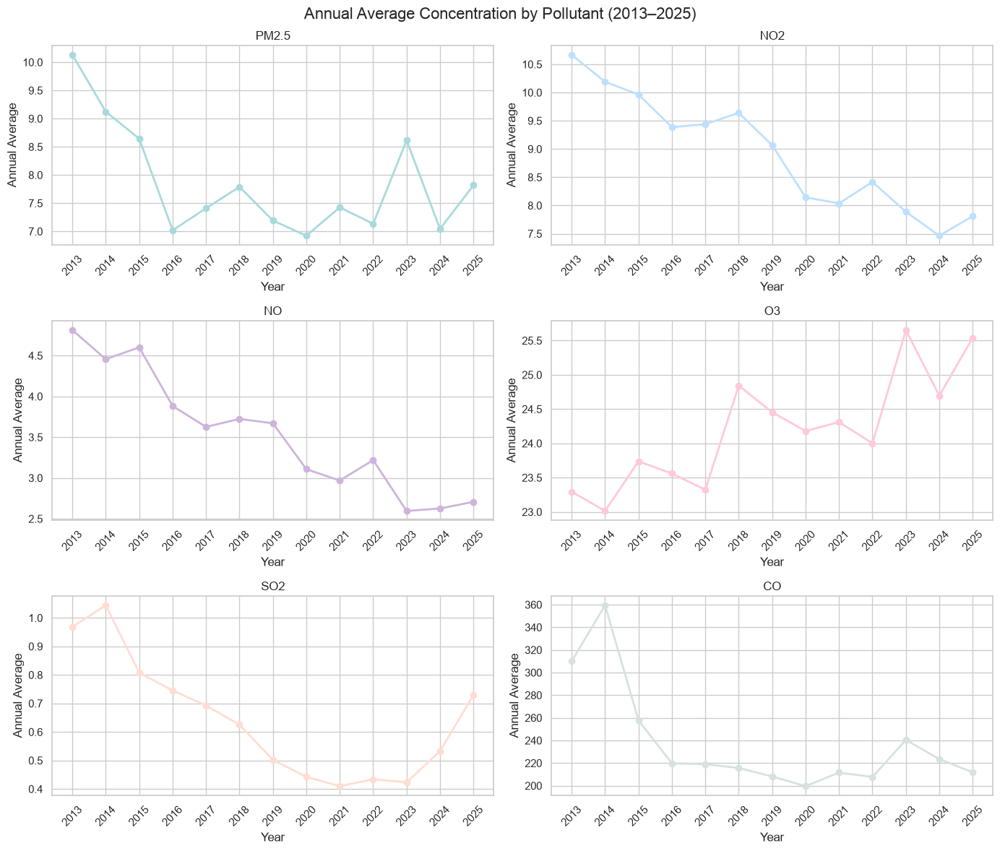

In [86]:
main_pollutants = [
    "PM2.5", "NO2", "NO", "O3", "SO2", "CO"
]

pastel_colors = [
    "#A8DADC",
    "#BDE0FE",
    "#CDB4DB",
    "#FFC8DD",
    "#FFDDD2",
    "#D8E2DC"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12)
)

for ax, pollutant, color in zip(
    axes.flat,
    main_pollutants,
    pastel_colors
):
    ax.plot(
        annual_means.index,
        annual_means[pollutant],
        marker="o",
        linewidth=2,
        color=color
    )

    ax.set_title(pollutant)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual Average")
    ax.set_xticks(annual_means.index)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Annual Average Concentration by Pollutant (2013–2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [87]:
change_2013_2025 = (
    (annual_means.loc[2025] - annual_means.loc[2013])
    / annual_means.loc[2013]
) * 100

print("Percentage Change: 2013 → 2025")
print("-" * 40)
print(change_2013_2025.round(2))

Percentage Change: 2013 → 2025
----------------------------------------
PM2.5   -22.84
NO2     -26.77
NO      -43.75
O3        9.64
SO2     -24.68
CO      -31.65
dtype: float64


---
### Annual Trend Observations

The annual averages show an overall decrease in most pollutant concentrations between 2013 and 2025. NO presents the largest reduction at **43.75%**, followed by CO (**31.65%**), NO2 (**26.77%**), SO2 (**24.68%**), and PM2.5 (**22.84%**).

In contrast, O3 is the only main pollutant showing an increase, with a **9.64%** change over the same period. Overall, the results indicate a general downward trend in the concentrations of most measured pollutants, while O3 follows a different pattern.

---